# Baseline Comparison — JalVaani
Loads prediction CSVs from all models that have been run and builds a unified comparison table + plots.  
**Run this after all baseline notebooks have been executed.**  
Designed to be extended — TFT and TFT+GAT prediction files will be picked up automatically when they exist.

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from IPython.display import display

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.size']  = 11

OUT_DIR = Path('outputs')
OUT_DIR.mkdir(exist_ok=True)
(OUT_DIR / 'plots').mkdir(exist_ok=True)

# Add TFT and TFT+GAT rows here when those prediction files exist
MODEL_FILES = {
    'SARIMA':   'arima_predictions.csv',
    'XGBoost':  'xgboost_predictions.csv',
    'LSTM':     'lstm_predictions.csv',
    # 'TFT':      'tft_predictions.csv',
    # 'TFT+GAT':  'tft_gat_predictions.csv',
}
PRED_COLS  = ['gwl_predicted', 'gwl_pred']
ACTUAL_COL = 'gwl_actual'

COLORS = {
    'SARIMA':  '#e41a1c',
    'XGBoost': '#ff7f00',
    'LSTM':    '#377eb8',
    'TFT':     '#4daf4a',
    'TFT+GAT': '#984ea3',
}

print('Config loaded ✓')

## 1. Load All Prediction Files

In [2]:
def load_preds(path):
    df = pd.read_csv(path)
    for col in PRED_COLS:
        if col in df.columns:
            return df.rename(columns={col: 'gwl_pred'})
    raise ValueError(f'No prediction column in {path}')

loaded = {}
for name, fname in MODEL_FILES.items():
    p = OUT_DIR / fname
    if p.exists():
        loaded[name] = load_preds(p)
        print(f'  ✅ {name:<10} — {len(loaded[name]):,} rows  ({fname})')
    else:
        print(f'  ❌ {name:<10} — not found ({fname})')

if not loaded:
    print('\nNo prediction files found. Run the baseline notebooks first.')

  ✅ SARIMA     — 132 rows  (arima_predictions.csv)
  ✅ XGBoost    — 3,975 rows  (xgboost_predictions.csv)
  ✅ LSTM       — 3,352 rows  (lstm_predictions.csv)


## 2. Aggregate Metrics Table

In [3]:
def compute_metrics(actual, pred):
    a, p = np.array(actual, float), np.array(pred, float)
    valid = ~(np.isnan(a) | np.isnan(p))
    a, p  = a[valid], p[valid]
    if len(a) == 0:
        return np.nan, np.nan, np.nan
    rmse = np.sqrt(np.mean((a-p)**2))
    mae  = np.mean(np.abs(a-p))
    mask = a != 0
    mape = np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100 if mask.any() else np.nan
    return rmse, mae, mape

rows = []
for name, df in loaded.items():
    val_df  = df[df['split']=='val']
    test_df = df[df['split']=='test']
    vr, vm, vp = compute_metrics(val_df[ACTUAL_COL],  val_df['gwl_pred'])
    tr, tm, tp = compute_metrics(test_df[ACTUAL_COL], test_df['gwl_pred'])
    rows.append({
        'Model':     name,
        'Val RMSE':  round(vr,4), 'Val MAE':  round(vm,4), 'Val MAPE':  round(vp,2),
        'Test RMSE': round(tr,4), 'Test MAE': round(tm,4), 'Test MAPE': round(tp,2),
    })

summary = pd.DataFrame(rows)
print('=== Baseline Comparison — Aggregate Results ===')
display(
    summary.style
    .background_gradient(subset=['Test RMSE','Test MAE','Test MAPE'], cmap='YlOrRd')
    .format({'Val RMSE':'{:.4f}','Val MAE':'{:.4f}','Val MAPE':'{:.2f}',
             'Test RMSE':'{:.4f}','Test MAE':'{:.4f}','Test MAPE':'{:.2f}'})
)

=== Baseline Comparison — Aggregate Results ===


,Model,Val RMSE,Val MAE,Val MAPE,Test RMSE,Test MAE,Test MAPE
0,SARIMA,90.8492,18.2621,376.34,3.6335,1.8725,16.22
1,XGBoost,0.5566,0.1957,6.10,1.6818,0.4616,2.43
2,LSTM,1.4465,0.7060,18.09,2.7346,1.0636,8.91


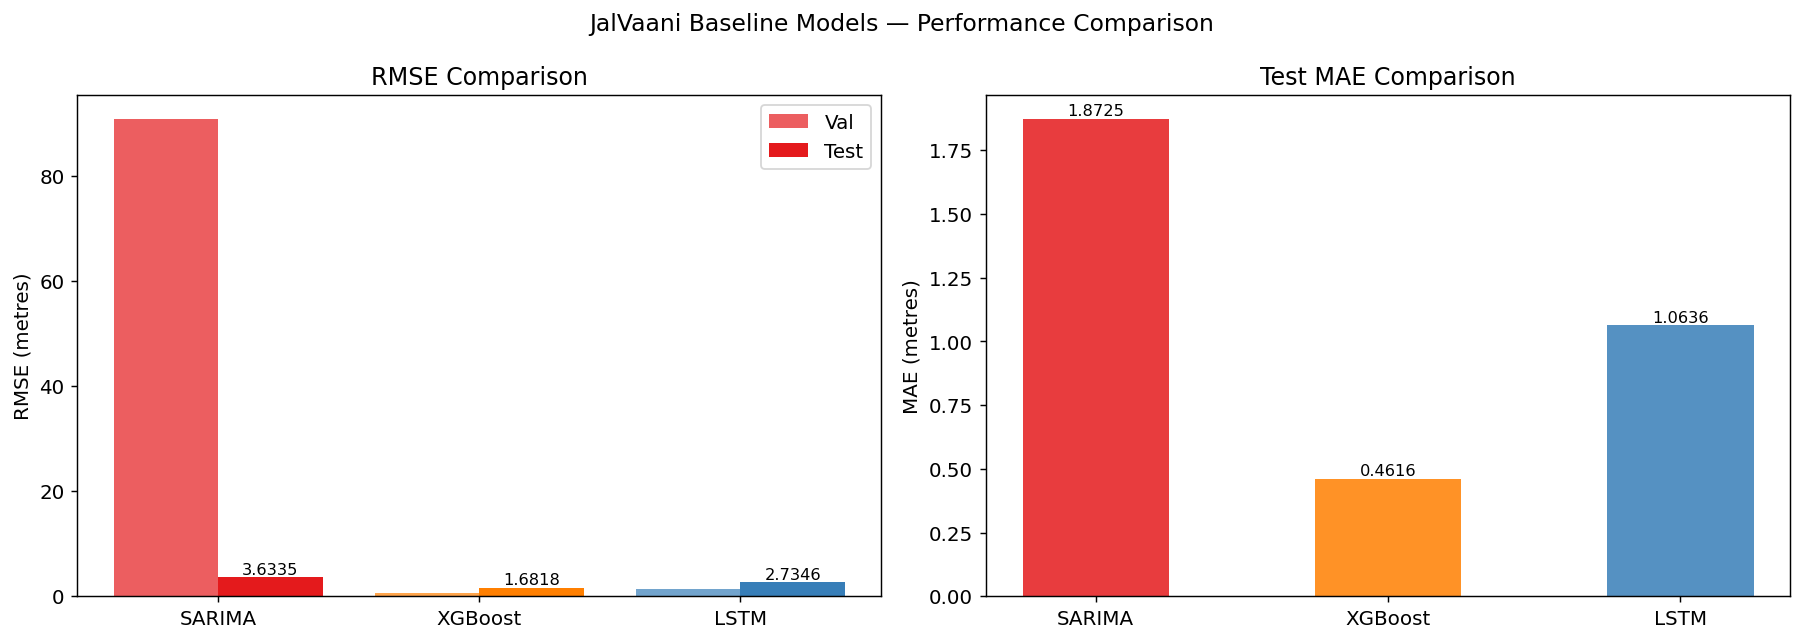

In [4]:
# RMSE comparison bar chart
models    = summary['Model'].tolist()
val_rmse  = summary['Val RMSE'].tolist()
test_rmse = summary['Test RMSE'].tolist()
x         = np.arange(len(models))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# RMSE
bars1 = axes[0].bar(x-0.2, val_rmse,  0.4, label='Val',  color=[COLORS.get(m,'gray') for m in models], alpha=0.7)
bars2 = axes[0].bar(x+0.2, test_rmse, 0.4, label='Test', color=[COLORS.get(m,'gray') for m in models], alpha=1.0)
axes[0].set_xticks(x)
axes[0].set_xticklabels(models)
axes[0].set_ylabel('RMSE (metres)')
axes[0].set_title('RMSE Comparison')
axes[0].legend()
for bar in bars2:
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
                 f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=9)

# MAE
test_mae = summary['Test MAE'].tolist()
axes[1].bar(x, test_mae, 0.5, color=[COLORS.get(m,'gray') for m in models], alpha=0.85)
axes[1].set_xticks(x)
axes[1].set_xticklabels(models)
axes[1].set_ylabel('MAE (metres)')
axes[1].set_title('Test MAE Comparison')
for i, v in enumerate(test_mae):
    axes[1].text(i, v+0.001, f'{v:.4f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('JalVaani Baseline Models — Performance Comparison', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR / 'plots' / 'comparison_bar.png', dpi=150)
plt.show()

## 3. Per-District Comparison

In [5]:
per_dist = {}
for name, df in loaded.items():
    test_df = df[df['split']=='test']
    if 'district' not in test_df.columns:
        continue
    dist_r = {}
    for dist, grp in test_df.groupby('district'):
        r, _, _ = compute_metrics(grp[ACTUAL_COL].values, grp['gwl_pred'].values)
        dist_r[dist] = round(r, 4)
    per_dist[name] = dist_r

if per_dist:
    all_dists = sorted(set(d for m in per_dist.values() for d in m))
    rows = [{'District': d, **{f'{m} RMSE': per_dist[m].get(d, np.nan) for m in per_dist}}
            for d in all_dists]
    dist_table = pd.DataFrame(rows)
    print('Per-District Test RMSE (metres):')
    rmse_cols = [c for c in dist_table.columns if 'RMSE' in c]
    display(dist_table.style.background_gradient(subset=rmse_cols, cmap='YlOrRd').format(
        {c: '{:.4f}' for c in rmse_cols}, na_rep='—'
    ))
    dist_table.to_csv(OUT_DIR / 'comparison_per_district.csv', index=False)

Per-District Test RMSE (metres):


,District,SARIMA RMSE,XGBoost RMSE,LSTM RMSE
0,Akola,0.6415,0.1276,1.0132
1,Amravati,0.4175,0.1161,0.4164
2,Aurangabad,7.5983,0.1965,0.9777
3,Beed,—,—,0.6098
4,Bhandara,—,0.1771,0.7212
5,Chandrapur,0.3576,0.0805,0.3361
6,Dhule,—,6.4567,10.8996
7,Gadchiroli,—,—,1.5593
8,Gondia,3.0685,—,0.8494
9,Jalgaon,11.3599,3.3596,5.8408


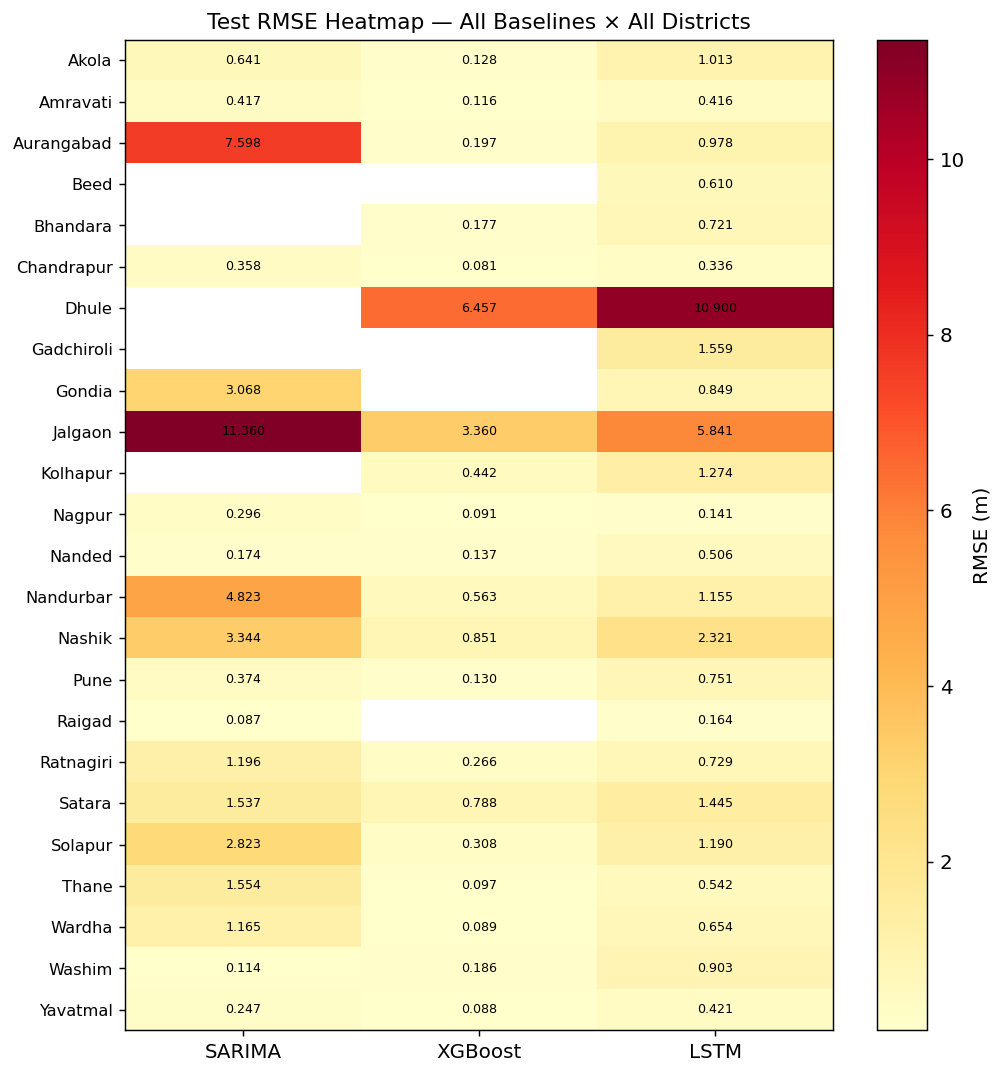

In [6]:
# Per-district heatmap — which model wins per district
if len(per_dist) > 1:
    rmse_matrix = dist_table.set_index('District')[[c for c in dist_table.columns if 'RMSE' in c]]
    rmse_matrix.columns = [c.replace(' RMSE','') for c in rmse_matrix.columns]

    fig, ax = plt.subplots(figsize=(max(8, len(rmse_matrix.columns)*2), max(6, len(all_dists)*0.35)))
    im = ax.imshow(rmse_matrix.values, aspect='auto', cmap='YlOrRd')
    ax.set_xticks(range(len(rmse_matrix.columns)))
    ax.set_xticklabels(rmse_matrix.columns)
    ax.set_yticks(range(len(all_dists)))
    ax.set_yticklabels(all_dists, fontsize=9)
    plt.colorbar(im, ax=ax, label='RMSE (m)')

    for i in range(len(all_dists)):
        for j in range(len(rmse_matrix.columns)):
            v = rmse_matrix.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f'{v:.3f}', ha='center', va='center', fontsize=7)

    ax.set_title('Test RMSE Heatmap — All Baselines × All Districts', fontsize=12)
    plt.tight_layout()
    plt.savefig(OUT_DIR / 'plots' / 'comparison_heatmap.png', dpi=150)
    plt.show()

## 4. Prediction Overlay — Best District from Each Model

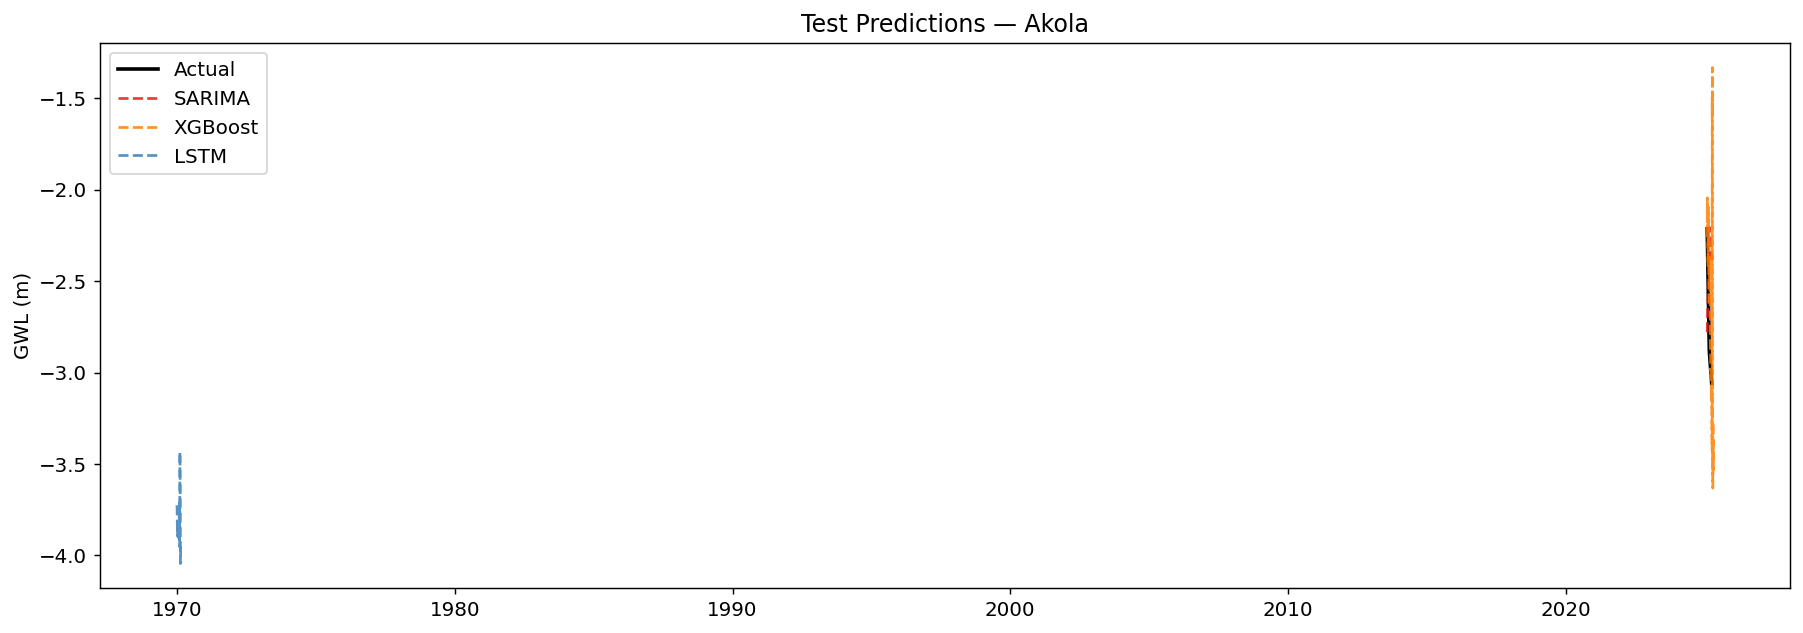

In [7]:
# Pick one district that all models cover; plot all predictions on the same axes
common_dists = None
for name, df in loaded.items():
    if 'district' not in df.columns: continue
    dists = set(df[df['split']=='test']['district'].unique())
    common_dists = dists if common_dists is None else common_dists & dists

if common_dists:
    plot_dist = sorted(common_dists)[0]  # pick first alphabetically
    fig, ax   = plt.subplots(figsize=(14, 5))

    actual_plotted = False
    for name, df in loaded.items():
        if 'district' not in df.columns: continue
        sub = df[(df['district']==plot_dist) & (df['split']=='test')].copy()
        if 'date' in sub.columns:
            sub = sub.sort_values('date')
            x_axis = pd.to_datetime(sub['date'])
        else:
            x_axis = range(len(sub))

        if not actual_plotted:
            ax.plot(x_axis, sub[ACTUAL_COL], label='Actual', color='black', linewidth=2)
            actual_plotted = True
        ax.plot(x_axis, sub['gwl_pred'], label=name, color=COLORS.get(name,'gray'),
                linewidth=1.5, linestyle='--', alpha=0.85)

    ax.set_title(f'Test Predictions — {plot_dist}')
    ax.set_ylabel('GWL (m)')
    ax.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / 'plots' / 'comparison_overlay.png', dpi=150)
    plt.show()
else:
    print('No common districts found across all models — skipping overlay plot.')

## 5. Save Summary

In [8]:
summary.to_csv(OUT_DIR / 'comparison_summary.csv', index=False)
print('Saved: comparison_summary.csv')
print('Saved: comparison_bar.png')
print('Saved: comparison_heatmap.png  (if multiple models)')
print('Saved: comparison_overlay.png  (if common districts found)')
print('Saved: comparison_per_district.csv')
print()
print('=== Final Summary ===')
display(summary[['Model','Test RMSE','Test MAE','Test MAPE']])

Saved: comparison_summary.csv
Saved: comparison_bar.png
Saved: comparison_heatmap.png  (if multiple models)
Saved: comparison_overlay.png  (if common districts found)
Saved: comparison_per_district.csv

=== Final Summary ===


,Model,Test RMSE,Test MAE,Test MAPE
0,SARIMA,3.6335,1.8725,16.22
1,XGBoost,1.6818,0.4616,2.43
2,LSTM,2.7346,1.0636,8.91
